<a href="https://colab.research.google.com/github/malachifletcher/bafad-research-track/blob/main/BAFAD_Week06_Exercise1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAFAD Week 6 — Exercise 1: Threshold-Based Anomaly Detection

**Name:** ___________________________  
**Week:** 6 · Nov 2–8, 2026  
**Commit message:** `feat: implement threshold-based anomaly detection and evaluate on SKAB`  
**Objective:** Set a percentile threshold from clean reconstruction errors; convert the
continuous error curve into binary anomaly predictions; compute precision, recall, and F1
for each synthetic SKAB file.

---

## Section 1: Setup & Imports

In [1]:
import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir('/content'))

Current folder: /content
Files: ['.config', 'sample_data']


In [2]:
%cd /content
!git clone https://github.com/malachifletcher/bafad-research-track.git

/content
Cloning into 'bafad-research-track'...
remote: Enumerating objects: 89, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 89 (delta 26), reused 1 (delta 1), pack-reused 34 (from 1)
Receiving objects: 100% (89/89), 1.49 MiB | 842.00 KiB/s, done.
Resolving deltas: 100% (29/29), done.


In [3]:
%cd /content/bafad-research-track

/content/bafad-research-track


In [4]:
%cd /content/bafad-research-track
!git pull origin main

/content/bafad-research-track
From https://github.com/malachifletcher/bafad-research-track
 * branch            main       -> FETCH_HEAD
Already up to date.


In [5]:
!mkdir -p week06

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import tensorflow as tf
from tensorflow import keras

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
tf.get_logger().setLevel('ERROR')

print(f'NumPy      version: {np.__version__}')
print(f'pandas     version: {pd.__version__}')
print(f'TensorFlow version: {tf.__version__}')
print('Imports successful.')

NumPy      version: 2.4.6
pandas     version: 2.2.3
TensorFlow version: 2.21.0
Imports successful.


## Section 2: Carry-Forward Functions from Weeks 3–5

Run this cell as-is.

In [7]:
def extract_anomaly_windows(anomaly_labels):
    """Converts binary label array to list of (start, end) tuples."""
    windows   = []
    in_window = False
    start     = 0
    for i, label in enumerate(anomaly_labels):
        if label == 1 and not in_window:
            start     = i
            in_window = True
        elif label == 0 and in_window:
            windows.append((start, i))
            in_window = False
    if in_window:
        windows.append((start, len(anomaly_labels)))
    return windows


def inject_noise_profile(raw_data, start_idx, end_idx, variance=2.5, mode='noise'):
    """Injects noise or blackout into a localized index window."""
    poisoned_data = raw_data.copy()
    window_rows   = end_idx - start_idx
    n_features    = poisoned_data.shape[1]
    if mode == 'noise':
        injection = np.random.normal(0, variance, size=(window_rows, n_features))
        poisoned_data[start_idx:end_idx, :] += injection
    elif mode == 'blackout':
        poisoned_data[start_idx:end_idx, :] = 0.0
    else:
        raise ValueError(f"Unknown mode: '{mode}'.")
    return poisoned_data


def make_windows(X, window_size=32, step=4):
    """
    Extracts overlapping sliding windows from a (T, F) sensor array.
    Returns (windows, starts) where windows.shape = (N, window_size, F).
    """
    T       = X.shape[0]
    starts  = np.arange(0, T - window_size + 1, step)
    windows = np.stack([X[s : s + window_size] for s in starts])
    return windows, starts


def reconstruction_error(model, X, window_size=32, step=4):
    """
    Computes per-window MSE reconstruction error for a sensor array.
    Returns (errors, indices) where errors.shape = (N,).
    """
    windows, indices = make_windows(X, window_size, step)
    reconstructed    = model.predict(windows.astype(np.float32), verbose=0)
    errors = np.mean((windows - reconstructed) ** 2, axis=(1, 2))
    return errors, indices


print('Carry-forward functions loaded.')

Carry-forward functions loaded.


## Section 3: Regenerate Synthetic SKAB Dataset and Reload Model

Run this cell as-is.

In [8]:
def make_synthetic_skab_file(filepath, n_rows, anomaly_windows, seed=0):
    np.random.seed(seed)
    t       = np.linspace(0, 50, n_rows)
    sensors = {}
    names   = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
                'Pressure', 'Temperature', 'Thermocouple',
                'Voltage', 'Volume Flow RateRMS']
    for i, name in enumerate(names):
        sensors[name] = np.sin(t * (i + 1)) + np.random.normal(0, 0.05, n_rows)
    labels      = np.zeros(n_rows, dtype=int)
    changepoint = np.zeros(n_rows, dtype=int)
    for s, e in anomaly_windows:
        labels[s:e]    = 1
        changepoint[s] = 1
    idx = pd.date_range('2020-01-01', periods=n_rows, freq='1s')
    df  = pd.DataFrame(sensors, index=idx)
    df.index.name = 'datetime'
    df['anomaly']     = labels
    df['changepoint'] = changepoint
    df.to_csv(filepath, sep=';')


synth_dir  = Path('synthetic_alldata')
synth_dir.mkdir(exist_ok=True)

files_spec = [
    ('1.csv', 800,  [(150, 230), (500, 580)]),
    ('2.csv', 1000, [(200, 350)]),
    ('3.csv', 600,  []),
    ('4.csv', 900,  [(100, 160), (400, 480), (700, 750)]),
    ('5.csv', 750,  [(300, 420)]),
]

for fname, n_rows, windows in files_spec:
    make_synthetic_skab_file(synth_dir / fname, n_rows, windows)

print('Synthetic SKAB dataset ready.')

# Load or retrain model
SENSOR_COLS = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
               'Pressure', 'Temperature', 'Thermocouple',
               'Voltage', 'Volume Flow RateRMS']
WINDOW_SIZE = 32
STEP        = 4
DATA_DIR    = Path('synthetic_alldata')   # swap to Path('SKAB/alldata') for real data
MODEL_PATH  = Path('autoencoder_week05.keras')

if MODEL_PATH.exists():
    model = tf.keras.models.load_model(MODEL_PATH)
    print(f'Model loaded from {MODEL_PATH}')
else:
    print('Model file not found — retraining from scratch...')
    def build_autoencoder(window_size=32, n_features=8):
        inp = keras.Input(shape=(window_size, n_features))
        x = keras.layers.Conv1D(16, 3, activation='relu', padding='same')(inp)
        x = keras.layers.MaxPooling1D(2)(x)
        x = keras.layers.Conv1D(8,  3, activation='relu', padding='same')(x)
        x = keras.layers.MaxPooling1D(2)(x)
        x = keras.layers.Conv1D(8,  3, activation='relu', padding='same')(x)
        x = keras.layers.UpSampling1D(2)(x)
        x = keras.layers.Conv1D(16, 3, activation='relu', padding='same')(x)
        x = keras.layers.UpSampling1D(2)(x)
        out = keras.layers.Conv1D(n_features, 3, activation='linear', padding='same')(x)
        m = keras.Model(inp, out)
        m.compile(optimizer='adam', loss='mse')
        return m
    df_clean = pd.read_csv(DATA_DIR / '3.csv', sep=';',
                           index_col='datetime', parse_dates=True)
    X_clean  = df_clean[SENSOR_COLS].values.astype(np.float32)
    X_train, _ = make_windows(X_clean, WINDOW_SIZE, STEP)
    tf.random.set_seed(42); np.random.seed(42)
    model = build_autoencoder(WINDOW_SIZE, X_train.shape[2])
    model.fit(X_train, X_train, epochs=15, batch_size=16,
              validation_split=0.1, verbose=1)
    model.save(MODEL_PATH)
    print(f'Model saved to {MODEL_PATH}')

print('Ready.')

Synthetic SKAB dataset ready.
Model file not found — retraining from scratch...
Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.4985 - val_loss: 0.4875
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4815 - val_loss: 0.4699
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4658 - val_loss: 0.4492
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.4480 - val_loss: 0.4282
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4300 - val_loss: 0.4081
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4122 - val_loss: 0.3878
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3935 - val_loss: 0.3672
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3728 - val_loss: 0.3447
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3504 - val_loss: 0.3205
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3279 - val_loss: 0.2977
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3057 - val_loss: 0.2747
Epoch 12/15
8/

## Section 4: Compute Training Errors

Run this cell as-is after Sections 2–3 complete successfully.

In [9]:
df_clean   = pd.read_csv(DATA_DIR / '3.csv', sep=';',
                         index_col='datetime', parse_dates=True)
X_clean    = df_clean[SENSOR_COLS].values.astype(np.float32)
errors_train, _ = reconstruction_error(model, X_clean, WINDOW_SIZE, STEP)

print(f'Training errors shape: {errors_train.shape}')
print(f'Min  : {errors_train.min():.6f}')
print(f'Mean : {errors_train.mean():.6f}')
print(f'95th : {np.percentile(errors_train, 95):.6f}')
print(f'99th : {np.percentile(errors_train, 99):.6f}')
print(f'Max  : {errors_train.max():.6f}')

Training errors shape: (143,)
Min  : 0.140036
Mean : 0.203670
95th : 0.285857
99th : 0.307156
Max  : 0.316681


## Section 5: Implement `set_threshold()`

Sets the anomaly detection threshold as a percentile of the clean training error distribution.

**Your task:** Complete the function body.

In [11]:

def set_threshold(errors_clean, percentile=99):
    """
    Sets an anomaly detection threshold from clean reconstruction errors.
    """
    return float(np.percentile(errors_clean, percentile))

## Section 6: Implement `predict_anomalies()`

Maps per-window binary predictions back to a timestep-level array.

**Your task:** Complete the function body.

In [12]:

def predict_anomalies(errors, indices, threshold, T, window_size):
    """
    Maps per-window binary predictions back to a timestep array.
    """
    pred = np.zeros(T, dtype=int)

    for err, start in zip(errors, indices):
        center = start + window_size // 2

        if center < T:
            pred[center] = int(err > threshold)

    return pred


def set_threshold(errors_clean, percentile=99):
    """
    Sets an anomaly detection threshold from clean reconstruction errors.
    """
    return float(np.percentile(errors_clean, percentile))


threshold_99 = set_threshold(errors_train, percentile=99)
threshold_95 = set_threshold(errors_train, percentile=95)

print(f'99th-percentile threshold: {threshold_99:.6f}')
print(f'95th-percentile threshold: {threshold_95:.6f}')

assert isinstance(threshold_99, float), 'threshold must be a Python float'
assert threshold_99 > 0, 'threshold must be positive'

print('set_threshold() checks passed.')


# Quick check on contaminated 4.csv
df4 = pd.read_csv(DATA_DIR / '4.csv', sep=';',
                  index_col='datetime', parse_dates=True)

X4 = df4[SENSOR_COLS].values.astype(np.float32)
labels4 = df4['anomaly'].values.astype(int)
windows4 = extract_anomaly_windows(labels4)

np.random.seed(42)
X4_cont = X4.copy()

for s, e in windows4:
    X4_cont = inject_noise_profile(
        X4_cont, s, e, variance=2.5, mode='noise'
    )

err4, idx4 = reconstruction_error(
    model, X4_cont, WINDOW_SIZE, STEP
)

pred4 = predict_anomalies(
    err4, idx4, threshold_99, len(labels4), WINDOW_SIZE
)

assert pred4.shape == labels4.shape, f'Shape mismatch: {pred4.shape} vs {labels4.shape}'
assert np.issubdtype(pred4.dtype, np.integer), 'pred must be integer'
assert set(np.unique(pred4)).issubset({0, 1}), 'pred must contain only 0s and 1s'

print(f'predict_anomalies() shape check passed: {pred4.shape}')
print(f'Predicted anomaly timesteps (4.csv contaminated): {pred4.sum()}')

99th-percentile threshold: 0.307156
95th-percentile threshold: 0.285857
set_threshold() checks passed.
predict_anomalies() shape check passed: (900,)
Predicted anomaly timesteps (4.csv contaminated): 80


## Section 7: Implement `compute_metrics()`

Computes precision, recall, and F1 from binary arrays.

**Your task:** Complete the function body.

In [13]:

def compute_metrics(labels, pred):
    """
    Computes precision, recall, and F1 from binary arrays.
    """
    tp = int(np.sum((pred == 1) & (labels == 1)))
    fp = int(np.sum((pred == 1) & (labels == 0)))
    fn = int(np.sum((pred == 0) & (labels == 1)))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0.0
    )

    return dict(
        tp=tp,
        fp=fp,
        fn=fn,
        precision=float(precision),
        recall=float(recall),
        f1=float(f1)
    )


m4 = compute_metrics(labels4, pred4)

print(f'4.csv (contaminated) — P={m4["precision"]:.3f}  R={m4["recall"]:.3f}  F1={m4["f1"]:.3f}')
print(f'  TP={m4["tp"]}  FP={m4["fp"]}  FN={m4["fn"]}')

assert isinstance(m4['precision'], float), 'precision must be float'
assert 0.0 <= m4['precision'] <= 1.0, 'precision out of range'
assert 0.0 <= m4['recall'] <= 1.0, 'recall out of range'
assert 0.0 <= m4['f1'] <= 1.0, 'F1 out of range'

print('compute_metrics() checks passed.')

4.csv (contaminated) — P=0.600  R=0.253  F1=0.356
  TP=48  FP=32  FN=142
compute_metrics() checks passed.


## Section 8: Implement `evaluate_file()` and Run Full Evaluation

**Your task:** Complete `evaluate_file()`. The evaluation loop and assertions run as-is.

In [14]:

def evaluate_file(model, filepath, sensor_cols, threshold,
                  window_size=32, step=4, noise_variance=2.5, seed=42):
    """
    Evaluates the autoencoder on one SKAB CSV file.
    Contaminates anomaly windows with noise before evaluation.
    """

    # Read CSV
    df = pd.read_csv(
        filepath,
        sep=';',
        index_col='datetime',
        parse_dates=True
    )

    # Extract sensor data and labels
    X = df[sensor_cols].values.astype(np.float32)
    labels = df['anomaly'].values.astype(int)
    T = len(labels)

    # Find anomaly windows
    windows = extract_anomaly_windows(labels)

    # Contaminate anomaly windows with noise
    np.random.seed(seed)
    X_cont = X.copy()

    for start, end in windows:
        X_cont = inject_noise_profile(
            X_cont,
            start,
            end,
            variance=noise_variance,
            mode='noise'
        )

    # Calculate reconstruction errors
    errors, indices = reconstruction_error(
        model,
        X_cont,
        window_size,
        step
    )

    # Predict anomalies
    pred = predict_anomalies(
        errors,
        indices,
        threshold,
        T,
        window_size
    )

    # Calculate metrics
    metrics = compute_metrics(labels, pred)

    # Add evaluation information
    metrics['filename'] = Path(filepath).name
    metrics['threshold'] = float(threshold)
    metrics['n_anomaly_ts'] = int(np.sum(labels == 1))
    metrics['n_windows'] = len(windows)

    return metrics


# Run evaluation on all files
THRESHOLD = threshold_99
results = []

for fname, _, _ in files_spec:
    row = evaluate_file(
        model,
        DATA_DIR / fname,
        SENSOR_COLS,
        THRESHOLD,
        WINDOW_SIZE,
        STEP
    )

    results.append(row)

    print(
        f"{row['filename']:8s}  anomaly_ts={row['n_anomaly_ts']:3d}  "
        f"P={row['precision']:.3f}  R={row['recall']:.3f}  "
        f"F1={row['f1']:.3f}"
    )


results_df = pd.DataFrame(results)[[
    'filename', 'n_anomaly_ts', 'tp', 'fp', 'fn',
    'precision', 'recall', 'f1', 'threshold'
]]

print('\nScorecard:')
print(results_df.to_string(index=False))


# Key assertions
row3 = next(r for r in results if r['filename'] == '3.csv')

assert row3['f1'] == 0.0, (
    f'3.csv has no anomalies — F1 must be 0.0, got {row3["f1"]}'
)

print('\nAssertion passed: 3.csv F1 = 0.0 (no anomalies in clean file).')

files_with_anomalies = [
    r for r in results if r['n_anomaly_ts'] > 0
]

f1_nonzero = [
    r for r in files_with_anomalies if r['f1'] > 0.0
]

assert len(f1_nonzero) > 0, (
    'At least one file with anomalies must have F1 > 0'
)

print(
    f'Assertion passed: {len(f1_nonzero)}/'
    f'{len(files_with_anomalies)} anomalous files have F1 > 0.'
)

1.csv     anomaly_ts=160  P=0.645  R=0.250  F1=0.360
2.csv     anomaly_ts=150  P=0.576  R=0.253  F1=0.352
3.csv     anomaly_ts=  0  P=0.000  R=0.000  F1=0.000
4.csv     anomaly_ts=190  P=0.600  R=0.253  F1=0.356
5.csv     anomaly_ts=120  P=0.667  R=0.250  F1=0.364

Scorecard:
filename  n_anomaly_ts  tp  fp  fn  precision   recall       f1  threshold
   1.csv           160  40  22 120   0.645161 0.250000 0.360360   0.307156
   2.csv           150  38  28 112   0.575758 0.253333 0.351852   0.307156
   3.csv             0   0   2   0   0.000000 0.000000 0.000000   0.307156
   4.csv           190  48  32 142   0.600000 0.252632 0.355556   0.307156
   5.csv           120  30  15  90   0.666667 0.250000 0.363636   0.307156

Assertion passed: 3.csv F1 = 0.0 (no anomalies in clean file).
Assertion passed: 4/4 anomalous files have F1 > 0.


## Section 9: Visualization

**Your task:** Fill in the TODO items to complete the two-panel figure.

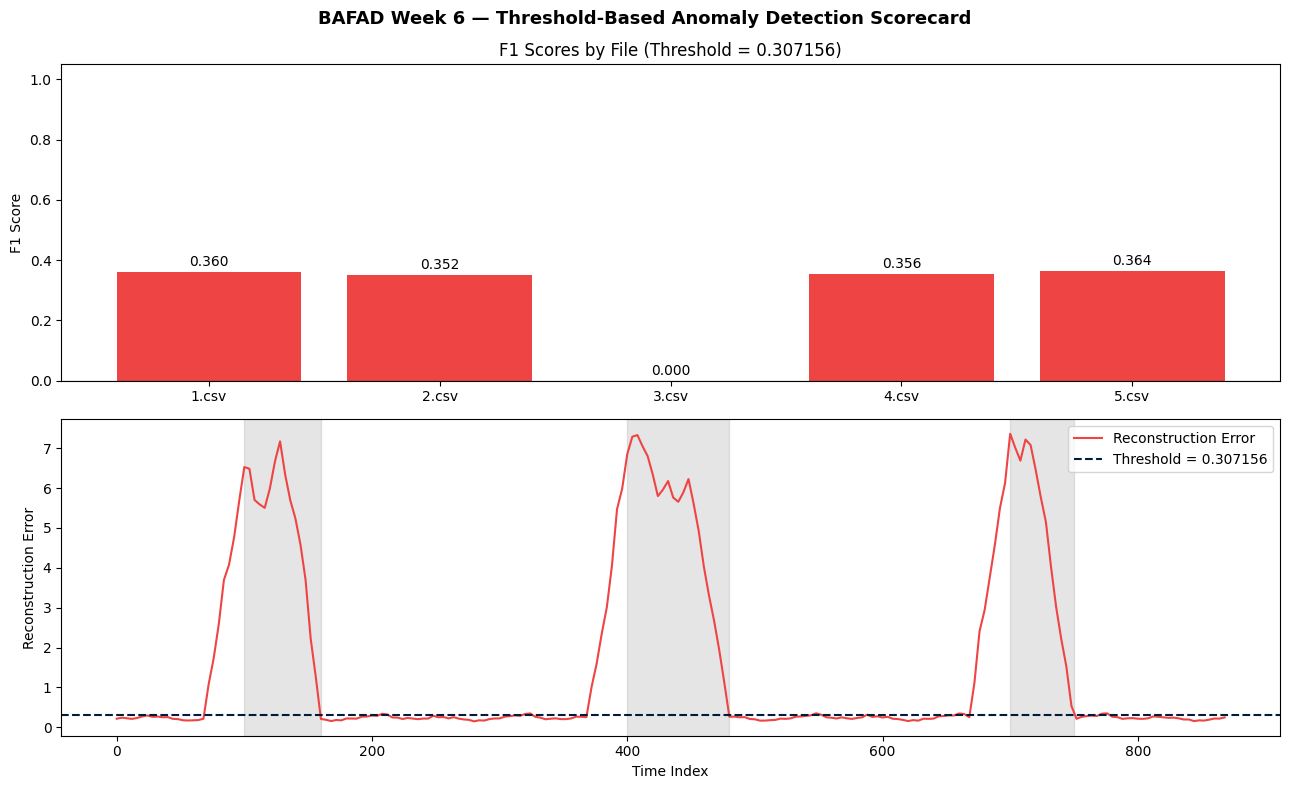

Plot saved to week06_exercise1_plot.png


In [20]:

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

filenames = [r['filename'] for r in results]
f1_scores = [r['f1'] for r in results]
colors = ['#EF4444' if f > 0 else '#94A3B8' for f in f1_scores]

# Top panel: F1-score bar chart
axes[0].bar(filenames, f1_scores, color=colors)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_ylabel('F1 Score')
axes[0].set_title(f'F1 Scores by File (Threshold = {THRESHOLD:.6f})')
axes[0].set_ylim(0, 1.05)

for i, f in enumerate(f1_scores):
    axes[0].text(i, f + 0.02, f'{f:.3f}', ha='center')

# Bottom panel: Reconstruction error for 4.csv
df4 = pd.read_csv(
    DATA_DIR / '4.csv',
    sep=';',
    index_col='datetime',
    parse_dates=True
)

X4 = df4[SENSOR_COLS].values.astype(np.float32)
labels4 = df4['anomaly'].values.astype(int)
windows4 = extract_anomaly_windows(labels4)

np.random.seed(42)
X4_cont = X4.copy()

for s, e in windows4:
    X4_cont = inject_noise_profile(
        X4_cont, s, e,
        variance=2.5,
        mode='noise'
    )

err4, idx4 = reconstruction_error(
    model, X4_cont, WINDOW_SIZE, STEP
)

axes[1].plot(idx4, err4, color='#EF4444', label='Reconstruction Error')

axes[1].axhline(
    THRESHOLD,
    color='#021B3A',
    linestyle='--',
    label=f'Threshold = {THRESHOLD:.6f}'
)

# Shade anomaly windows
for s, e in windows4:
    axes[1].axvspan(s, e, color='gray', alpha=0.2)

axes[1].set_ylabel('Reconstruction Error')
axes[1].set_xlabel('Time Index')
axes[1].legend()

# Finish and save figure
fig.suptitle(
    'BAFAD Week 6 — Threshold-Based Anomaly Detection Scorecard',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig(
    'week06_exercise1_plot.png',
    dpi=150,
    bbox_inches='tight'
)
plt.show()

print('Plot saved to week06_exercise1_plot.png')

In [19]:

!git add week06/BAFAD_Week06_Exercise1.ipynb
!git add week06/week06_exercise1_plot.png
!git commit -m "feat: implement threshold-based anomaly detection and evaluate on SKAB"
!git push origin main

fatal: pathspec 'week06/BAFAD_Week06_Exercise1.ipynb' did not match any files
fatal: pathspec 'week06/week06_exercise1_plot.png' did not match any files
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	autoencoder_week05.keras
	synthetic_alldata/
	week06_exercise1_plot.png

nothing added to commit but untracked files present (use "git add" to track)
fatal: could not read Username for 'https://github.com': No such device or address


## Section 10: Interpretation Questions

Answer each question in 2–4 sentences.

**Q1.** The threshold is set at the 99th percentile of clean training errors. What does this choice
imply about the expected false positive rate on clean test data?

> *Using the 99th percentile means that about 1% of the clean training errors are above the threshold. This suggests that the model may have a small false positive rate on clean test data, but it is not guaranteed to be exactly 1%.*

**Q2.** File 3.csv has zero anomaly rows. What values do you expect for precision, recall,
and F1 after running `evaluate_file()` on it? Explain why.

> *Precision, recall, and F1 are all expected to be 0.0. Since 3.csv has no actual anomaly rows and no true positives, there are no correct anomaly detections. The function sets these metrics to zero when their calculations would otherwise involve division by zero.*

**Q3.** A student changes the threshold from the 99th to the 50th percentile. Describe what
happens to precision and recall on the anomalous files, and explain the direction of each change.

> *Changing the threshold from the 99th to the 50th percentile makes it much easier for the model to flag an anomaly. Recall will usually increase because more actual anomalies are detected, but precision will usually decrease because more normal data may be incorrectly flagged as anomalous.*

## Section 11: Git Commit

```bash
git add week06/BAFAD_Week06_Exercise1.ipynb
git commit -m "feat: implement threshold-based anomaly detection and evaluate on SKAB"
git push origin main
```

In [17]:

!pwd
!ls

/content/bafad-research-track
autoencoder_week05.keras  synthetic_alldata  task-c  week05
data			  task-a	     week03  week06
README.md		  task-b	     week04  week06_exercise1_plot.png


In [21]:

!git config --global user.name "malachifletcher"
!git config --global user.email "imabossyoooo@gmail.com"

In [22]:
!ls -lah week06

total 8.0K
drwxr-xr-x  2 root root 4.0K Nov 10 14:17 .
drwxr-xr-x 12 root root 4.0K Nov 10 14:22 ..


In [24]:
!find /content -name "BAFAD_Week06_Exercise1.ipynb"

In [25]:
!find /content -name "week06_exercise1_plot.png"

/content/bafad-research-track/week06_exercise1_plot.png
